##Given the same candidate SNP set, does changing the ancestry of the LD reference change which variants survive LD clumping?

Notebook introduction and scientific aim

Mount Google Drive

Define project paths and thresholds

Define the four pipelines

Verify all clumping outputs

Load candidate SNP counts from the four pipelines

Load all chromosome-specific clumping results

Construct the index-SNP dataset

Count index SNPs by threshold and pipeline

Calculate candidate → index retention rates

Compare AFR-GWAS LD-reference pairs

Compare EUR-GWAS LD-reference pairs

Compare index-SNP identities

Calculate overlap and Jaccard similarity

Examine chromosome distribution

Examine threshold sensitivity

Produce a master LD comparison table

Generate figures

Save standardized outputs

Final QC

# LD Clumping Comparison
This notebook evaluates whether the ancestry of the LD reference panel changes the selection of approximately independent SNPs during T2D PRS construction.

The four PRS pipelines are:

- AFR–AFR: African-ancestry GWAS + African LD reference
- AFR–EUR: African-ancestry GWAS + European LD reference
- EUR–AFR: European-ancestry GWAS + African LD reference
- EUR–EUR: European-ancestry GWAS + European LD reference

Candidate SNP selection occurs before LD clumping and is determined by the discovery GWAS and P-value threshold. Therefore, pipelines using the same GWAS should have identical candidate SNP sets before clumping.

The primary comparisons in this notebook are:

1. AFR–AFR vs AFR–EUR
   - Same African GWAS
   - Different LD reference ancestries

2. EUR–AFR vs EUR–EUR
   - Same European GWAS
   - Different LD reference ancestries

These comparisons isolate the effect of LD-reference ancestry within each discovery-GWAS ancestry.

## Main question

When the same GWAS evidence is used, does changing the ancestry of the LD reference change which variants survive LD clumping?

## Main outcomes

For each P-value threshold, this notebook evaluates:

- Number of index SNPs
- Candidate-to-index retention rate
- Index-SNP overlap
- Jaccard similarity
- Chromosomal distribution
- Threshold-dependent patterns

The results provide the primary analysis of the LD-reference ancestry component of the study.

## Mount Google Drive

Google Drive is mounted to provide persistent storage for the project files and intermediate results.

Using persistent storage prevents the loss of large reference datasets and computational outputs when the Colab runtime is disconnected or restarted.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


## Imports and project paths

In [ ]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Four completed PRS pipelines
PROJECT_AFR_AFR = Path("/content/drive/MyDrive/PRS_T2D")
PROJECT_AFR_EUR = Path("/content/drive/MyDrive/PRS_T2D_A-E")
PROJECT_EUR_AFR = Path("/content/drive/MyDrive/PRS_T2D_E-A")
PROJECT_EUR_EUR = Path("/content/drive/MyDrive/PRS_T2D_E-E")

# P-value thresholds
THRESHOLDS = {
    "P5e-08": 5e-8,
    "P1e-05": 1e-5,
    "P0.0001": 1e-4,
    "P0.001": 1e-3,
    "P0.01": 1e-2,
    "P0.05": 5e-2
}

CHROMOSOMES = list(range(1, 23))

print("Projects and thresholds defined.")

Projects and thresholds defined.


# Define the clumping directories

In [ ]:
LD_DIRS = {
    "AFR-AFR": PROJECT_AFR_AFR / "results" / "ld_clumping" / "threshold_clumps",
    "AFR-EUR": PROJECT_AFR_EUR / "results" / "ld_clumping" / "threshold_clumps",
    "EUR-AFR": PROJECT_EUR_AFR / "results" / "ld_clumping" / "threshold_clumps",
    "EUR-EUR": PROJECT_EUR_EUR / "results" / "ld_clumping" / "threshold_clumps"
}

for pipeline, path in LD_DIRS.items():
    print(f"{pipeline}: {path}")

AFR-AFR: /content/drive/MyDrive/PRS_T2D/results/ld_clumping/threshold_clumps
AFR-EUR: /content/drive/MyDrive/PRS_T2D_A-E/results/ld_clumping/threshold_clumps
EUR-AFR: /content/drive/MyDrive/PRS_T2D_E-A/results/ld_clumping/threshold_clumps
EUR-EUR: /content/drive/MyDrive/PRS_T2D_E-E/results/ld_clumping/threshold_clumps


## Verify the clumping outputs before analysis

In [ ]:
print("Checking threshold directories...\n")

for pipeline, base_dir in LD_DIRS.items():
    print(f"{pipeline}")

    for threshold in THRESHOLDS:
        threshold_dir = base_dir / threshold

        print(
            f"  {threshold}: "
            f"{'FOUND' if threshold_dir.exists() else 'MISSING'}"
        )

    print()

Checking threshold directories...

AFR-AFR
  P5e-08: FOUND
  P1e-05: FOUND
  P0.0001: FOUND
  P0.001: FOUND
  P0.01: FOUND
  P0.05: FOUND

AFR-EUR
  P5e-08: FOUND
  P1e-05: FOUND
  P0.0001: FOUND
  P0.001: FOUND
  P0.01: FOUND
  P0.05: FOUND

EUR-AFR
  P5e-08: FOUND
  P1e-05: FOUND
  P0.0001: FOUND
  P0.001: FOUND
  P0.01: FOUND
  P0.05: FOUND

EUR-EUR
  P5e-08: FOUND
  P1e-05: FOUND
  P0.0001: FOUND
  P0.001: FOUND
  P0.01: FOUND
  P0.05: FOUND



## Verify chromosome-specific clump files

The clumping workflow produced up to:

6 thresholds × 22 chromosomes = 132 clumping outputs per pipeline.

Therefore:

132 × 4 = 528 potential clump files

Some may legitimately contain no index SNPs, particularly for stringent thresholds/chromosomes.

In [ ]:
clump_inventory = []

for pipeline, base_dir in LD_DIRS.items():

    for threshold in THRESHOLDS:

        threshold_dir = base_dir / threshold

        for chrom in CHROMOSOMES:

            clump_file = threshold_dir / f"clump_chr{chrom}.clumps"

            clump_inventory.append({
                "Pipeline": pipeline,
                "Threshold": threshold,
                "Chromosome": chrom,
                "Path": clump_file,
                "Exists": clump_file.exists()
            })

clump_inventory = pd.DataFrame(clump_inventory)

print("Total expected clump files:", len(clump_inventory))
print(
    "Files present:",
    clump_inventory["Exists"].sum()
)
print(
    "Files missing:",
    (~clump_inventory["Exists"]).sum()
)

display(clump_inventory)

Total expected clump files: 528
Files present: 526
Files missing: 2


,Pipeline,Threshold,Chromosome,Path,Exists
0,AFR-AFR,P5e-08,1,/content/drive/MyDrive/PRS_T2D/results/ld_clum...,True
1,AFR-AFR,P5e-08,2,/content/drive/MyDrive/PRS_T2D/results/ld_clum...,True
2,AFR-AFR,P5e-08,3,/content/drive/MyDrive/PRS_T2D/results/ld_clum...,True
3,AFR-AFR,P5e-08,4,/content/drive/MyDrive/PRS_T2D/results/ld_clum...,True
4,AFR-AFR,P5e-08,5,/content/drive/MyDrive/PRS_T2D/results/ld_clum...,True
...,...,...,...,...,...
523,EUR-EUR,P0.05,18,/content/drive/MyDrive/PRS_T2D_E-E/results/ld_...,True
524,EUR-EUR,P0.05,19,/content/drive/MyDrive/PRS_T2D_E-E/results/ld_...,True
525,EUR-EUR,P0.05,20,/content/drive/MyDrive/PRS_T2D_E-E/results/ld_...,True
526,EUR-EUR,P0.05,21,/content/drive/MyDrive/PRS_T2D_E-E/results/ld_...,True


*There were no P ≤ 5 × 10⁻⁸ African-GWAS candidates on chromosome 21, so neither LD reference had anything to clump on chromosome 21.*

## Load candidate SNP counts

Retention rate=
(Index SNPs​×100)/ Candidate SNPs

In [ ]:
#Define candidate directories
CANDIDATE_DIRS = {
    "AFR-AFR": PROJECT_AFR_AFR / "results" / "candidate_snps",
    "AFR-EUR": PROJECT_AFR_EUR / "results" / "candidate_snps",
    "EUR-AFR": PROJECT_EUR_AFR / "results" / "candidate_snps",
    "EUR-EUR": PROJECT_EUR_EUR / "results" / "candidate_snps"
}

for pipeline, path in CANDIDATE_DIRS.items():
    print(f"{pipeline}: {path}")

AFR-AFR: /content/drive/MyDrive/PRS_T2D/results/candidate_snps
AFR-EUR: /content/drive/MyDrive/PRS_T2D_A-E/results/candidate_snps
EUR-AFR: /content/drive/MyDrive/PRS_T2D_E-A/results/candidate_snps
EUR-EUR: /content/drive/MyDrive/PRS_T2D_E-E/results/candidate_snps


In [ ]:
# Define exact candidate filenames
CANDIDATE_FILENAMES = {
    "AFR-AFR": {
        threshold: f"T2D_PheCode250_2_{threshold}.tsv"
        for threshold in THRESHOLDS
    },

    "AFR-EUR": {
        threshold: f"T2D_PheCode250_2_{threshold}.tsv"
        for threshold in THRESHOLDS
    },

    "EUR-AFR": {
        threshold: f"MVP_T2D_Phe_250_2_EUR_{threshold}.tsv"
        for threshold in THRESHOLDS
    },

    "EUR-EUR": {
        threshold: f"MVP_T2D_Phe_250_2_EUR_{threshold}.tsv"
        for threshold in THRESHOLDS
    }
}

CANDIDATE_FILENAMES

{'AFR-AFR': {'P5e-08': 'T2D_PheCode250_2_P5e-08.tsv',
  'P1e-05': 'T2D_PheCode250_2_P1e-05.tsv',
  'P0.0001': 'T2D_PheCode250_2_P0.0001.tsv',
  'P0.001': 'T2D_PheCode250_2_P0.001.tsv',
  'P0.01': 'T2D_PheCode250_2_P0.01.tsv',
  'P0.05': 'T2D_PheCode250_2_P0.05.tsv'},
 'AFR-EUR': {'P5e-08': 'T2D_PheCode250_2_P5e-08.tsv',
  'P1e-05': 'T2D_PheCode250_2_P1e-05.tsv',
  'P0.0001': 'T2D_PheCode250_2_P0.0001.tsv',
  'P0.001': 'T2D_PheCode250_2_P0.001.tsv',
  'P0.01': 'T2D_PheCode250_2_P0.01.tsv',
  'P0.05': 'T2D_PheCode250_2_P0.05.tsv'},
 'EUR-AFR': {'P5e-08': 'MVP_T2D_Phe_250_2_EUR_P5e-08.tsv',
  'P1e-05': 'MVP_T2D_Phe_250_2_EUR_P1e-05.tsv',
  'P0.0001': 'MVP_T2D_Phe_250_2_EUR_P0.0001.tsv',
  'P0.001': 'MVP_T2D_Phe_250_2_EUR_P0.001.tsv',
  'P0.01': 'MVP_T2D_Phe_250_2_EUR_P0.01.tsv',
  'P0.05': 'MVP_T2D_Phe_250_2_EUR_P0.05.tsv'},
 'EUR-EUR': {'P5e-08': 'MVP_T2D_Phe_250_2_EUR_P5e-08.tsv',
  'P1e-05': 'MVP_T2D_Phe_250_2_EUR_P1e-05.tsv',
  'P0.0001': 'MVP_T2D_Phe_250_2_EUR_P0.0001.tsv',
  'P0.001

In [ ]:
# Calculate candidate counts
candidate_counts = []

for pipeline in CANDIDATE_DIRS:

    for threshold in THRESHOLDS:

        candidate_file = (
            CANDIDATE_DIRS[pipeline]
            / CANDIDATE_FILENAMES[pipeline][threshold]
        )

        if not candidate_file.exists():
            raise FileNotFoundError(
                f"Missing candidate file:\n{candidate_file}"
            )

        df = pd.read_csv(candidate_file, sep="\t")

        df["SNP"] = (
            df["SNP"]
            .astype(str)
            .str.strip()
        )

        candidate_counts.append({
            "Pipeline": pipeline,
            "Threshold": threshold,
            "P_threshold": THRESHOLDS[threshold],
            "Candidate_SNPs": df["SNP"].nunique()
        })

candidate_counts = pd.DataFrame(candidate_counts)

display(candidate_counts)


,Pipeline,Threshold,P_threshold,Candidate_SNPs
0,AFR-AFR,P5e-08,5.000000e-08,27292
1,AFR-AFR,P1e-05,1.000000e-05,64638
2,AFR-AFR,P0.0001,1.000000e-04,104274
3,AFR-AFR,P0.001,1.000000e-03,197201
4,AFR-AFR,P0.01,1.000000e-02,528446
5,AFR-AFR,P0.05,5.000000e-02,1500187
6,AFR-EUR,P5e-08,5.000000e-08,27292
7,AFR-EUR,P1e-05,1.000000e-05,64638
8,AFR-EUR,P0.0001,1.000000e-04,104274
9,AFR-EUR,P0.001,1.000000e-03,197201


## Load the actual LD-clumping results

Each .clumps file represents the result of LD clumping for:

one pipeline
one P-value threshold
one chromosome

The important field is:

**SNP**

It represents the index SNP selected by PLINK's clumping procedure.

In [ ]:
# Function to read one PLINK clumping output file

def read_clump_file(clump_file):
    """
    Read one PLINK .clumps output file.

    PLINK stores the index SNP in the 'ID' column.
    This function renames that column to 'SNP' so that
    all downstream comparison code uses a consistent SNP column.

    Returns:
        DataFrame containing clumping results.
        Empty DataFrame if the file is missing, empty,
        unreadable, or contains no usable index SNPs.
    """

    if not clump_file.exists():
        return pd.DataFrame()

    try:
        df = pd.read_csv(
            clump_file,
            sep="\t"
        )
    except Exception as e:
        print(f"Could not read {clump_file}: {e}")
        return pd.DataFrame()

    if df.empty:
        return pd.DataFrame()

    # PLINK stores the index SNP in the ID column
    if "ID" not in df.columns:
        print(f"'ID' column not found in {clump_file}")
        print("Columns found:", list(df.columns))
        return pd.DataFrame()

    # Rename PLINK's index-SNP column to the standardized name
    df = df.rename(columns={"ID": "SNP"})

    # Clean SNP identifiers
    df["SNP"] = (
        df["SNP"]
        .astype(str)
        .str.strip()
    )

    # Remove invalid/missing SNP identifiers
    df = df[
        df["SNP"].notna() &
        (df["SNP"] != "") &
        (df["SNP"] != "nan")
    ].copy()

    return df

## Build the complete index-SNP dataset

In [ ]:
# Read all chromosome-specific clump files
# and extract the index SNP from the PLINK 'ID' column.

index_records = []

for pipeline, base_dir in LD_DIRS.items():

    for threshold in THRESHOLDS:

        threshold_dir = base_dir / threshold

        for chrom in CHROMOSOMES:

            clump_file = (
                threshold_dir
                / f"clump_chr{chrom}.clumps"
            )

            # Expected missing files are handled as zero index SNPs
            if not clump_file.exists():
                continue

            clump_df = read_clump_file(clump_file)

            if clump_df.empty:
                continue

            for _, row in clump_df.iterrows():

                index_records.append({
                    "Pipeline": pipeline,
                    "Threshold": threshold,
                    "P_threshold": THRESHOLDS[threshold],
                    "Chromosome": chrom,
                    "SNP": row["SNP"],
                    "Clump_File": str(clump_file)
                })

index_snps = pd.DataFrame(index_records)

print("Total index-SNP records:", len(index_snps))

display(index_snps.head())

Total index-SNP records: 3663945


,Pipeline,Threshold,P_threshold,Chromosome,SNP,Clump_File
0,AFR-AFR,P5e-08,5.000000e-08,1,rs340882,/content/drive/MyDrive/PRS_T2D/results/ld_clum...
1,AFR-AFR,P5e-08,5.000000e-08,1,rs340878,/content/drive/MyDrive/PRS_T2D/results/ld_clum...
2,AFR-AFR,P5e-08,5.000000e-08,1,rs1431985,/content/drive/MyDrive/PRS_T2D/results/ld_clum...
3,AFR-AFR,P5e-08,5.000000e-08,1,rs79687284,/content/drive/MyDrive/PRS_T2D/results/ld_clum...
4,AFR-AFR,P5e-08,5.000000e-08,1,rs61779275,/content/drive/MyDrive/PRS_T2D/results/ld_clum...


## Check whether index SNPs are duplicated

In [ ]:
# Index SNP duplicate QC

index_duplicate_check = (
    index_snps
    .groupby(["Pipeline", "Threshold", "SNP"])
    .size()
    .reset_index(name="Occurrences")
)

duplicate_index_records = index_duplicate_check[
    index_duplicate_check["Occurrences"] > 1
]

print(
    "Duplicate index-SNP records:",
    len(duplicate_index_records)
)

if len(duplicate_index_records) > 0:
    display(duplicate_index_records.head(20))
else:
    print("No duplicate index SNPs detected within pipeline-threshold groups.")


Duplicate index-SNP records: 0
No duplicate index SNPs detected within pipeline-threshold groups.


## Calculate index-SNP counts

In [ ]:
# Index SNP counts
index_counts = (
    index_snps
    .groupby(["Pipeline", "Threshold", "P_threshold"])["SNP"]
    .nunique()
    .reset_index(name="Index_SNPs")
)

index_counts

,Pipeline,Threshold,P_threshold,Index_SNPs
0,AFR-AFR,P0.0001,1.000000e-04,7666
1,AFR-AFR,P0.001,1.000000e-03,19691
2,AFR-AFR,P0.01,1.000000e-02,90187
3,AFR-AFR,P0.05,5.000000e-02,357804
4,AFR-AFR,P1e-05,1.000000e-05,4305
5,AFR-AFR,P5e-08,5.000000e-08,1710
6,AFR-EUR,P0.0001,1.000000e-04,3302
7,AFR-EUR,P0.001,1.000000e-03,11288
8,AFR-EUR,P0.01,1.000000e-02,74325
9,AFR-EUR,P0.05,5.000000e-02,358128


## Combine candidate and index counts

In [ ]:
# Candidate-to-index summary
ld_summary = candidate_counts.merge(
    index_counts,
    on=[
        "Pipeline",
        "Threshold",
        "P_threshold"
    ],
    how="left"
)

ld_summary["Index_SNPs"] = (
    ld_summary["Index_SNPs"]
    .fillna(0)
    .astype(int)
)

ld_summary["Retention_Rate_pct"] = (
    ld_summary["Index_SNPs"]
    / ld_summary["Candidate_SNPs"]
    * 100
)

ld_summary

,Pipeline,Threshold,P_threshold,Candidate_SNPs,Index_SNPs,Retention_Rate_pct
0,AFR-AFR,P5e-08,5.000000e-08,27292,1710,6.265572
1,AFR-AFR,P1e-05,1.000000e-05,64638,4305,6.660169
2,AFR-AFR,P0.0001,1.000000e-04,104274,7666,7.351785
3,AFR-AFR,P0.001,1.000000e-03,197201,19691,9.985243
4,AFR-AFR,P0.01,1.000000e-02,528446,90187,17.066455
5,AFR-AFR,P0.05,5.000000e-02,1500187,357804,23.850627
6,AFR-EUR,P5e-08,5.000000e-08,27292,633,2.319361
7,AFR-EUR,P1e-05,1.000000e-05,64638,1636,2.531019
8,AFR-EUR,P0.0001,1.000000e-04,104274,3302,3.166657
9,AFR-EUR,P0.001,1.000000e-03,197201,11288,5.724109


Why **retention rate** is important

Suppose:

Pipeline A:

100,000 candidates → 20,000 index SNPs

Pipeline B:

100,000 candidates → 15,000 index SNPs

Then:

A retains 20%
B retains 15%

This tells us something about how the two LD references resolve correlated variants.

But suppose instead:

Pipeline A:

100,000 → 20,000

Pipeline B:

200,000 → 25,000

Simply comparing 20,000 vs 25,000 can be misleading because the starting candidate pools differ.

The retention rate normalizes this.

That is why we report both absolute index-SNP count and retention rate.

## Compare the LD references within the GWAS

In [ ]:
# AFR-GWAS LD comparison

afr_ld_comparison = (
    ld_summary[
        ld_summary["Pipeline"].isin(
            ["AFR-AFR", "AFR-EUR"]
        )
    ]
    .pivot(
        index="Threshold",
        columns="Pipeline",
        values=[
            "Candidate_SNPs",
            "Index_SNPs",
            "Retention_Rate_pct"
        ]
    )
)

afr_ld_comparison

Candidate_SNPs            Index_SNPs           Retention_Rate_pct  \
Pipeline         AFR-AFR    AFR-EUR    AFR-AFR   AFR-EUR            AFR-AFR   
Threshold                                                                     
P0.0001         104274.0   104274.0     7666.0    3302.0           7.351785   
P0.001          197201.0   197201.0    19691.0   11288.0           9.985243   
P0.01           528446.0   528446.0    90187.0   74325.0          17.066455   
P0.05          1500187.0  1500187.0   357804.0  358128.0          23.850627   
P1e-05           64638.0    64638.0     4305.0    1636.0           6.660169   
P5e-08           27292.0    27292.0     1710.0     633.0           6.265572   

                      
Pipeline     AFR-EUR  
Threshold             
P0.0001     3.166657  
P0.001      5.724109  
P0.01      14.064824  
P0.05      23.872224  
P1e-05      2.531019  
P5e-08      2.319361

In [ ]:
# EUR GWAS LD comparison
eur_ld_comparison = (
    ld_summary[
        ld_summary["Pipeline"].isin(
            ["EUR-AFR", "EUR-EUR"]
        )
    ]
    .pivot(
        index="Threshold",
        columns="Pipeline",
        values=[
            "Candidate_SNPs",
            "Index_SNPs",
            "Retention_Rate_pct"
        ]
    )
)

eur_ld_comparison

Candidate_SNPs            Index_SNPs           Retention_Rate_pct  \
Pipeline         EUR-AFR    EUR-EUR    EUR-AFR   EUR-EUR            EUR-AFR   
Threshold                                                                     
P0.0001         274975.0   274975.0    37511.0   25465.0          13.641604   
P0.001          555660.0   555660.0   107335.0   83925.0          19.316668   
P0.01          1396298.0  1396298.0   364262.0  319256.0          26.087698   
P0.05          3066477.0  3066477.0   920240.0  842495.0          30.009682   
P1e-05          161236.0   161236.0    16558.0    9216.0          10.269419   
P5e-08           66996.0    66996.0     4944.0    2063.0           7.379545   

                      
Pipeline     EUR-EUR  
Threshold             
P0.0001     9.260842  
P0.001     15.103661  
P0.01      22.864460  
P0.05      27.474362  
P1e-05      5.715845  
P5e-08      3.079288

## Calculate the direct LD-reference differences

To check whether the number of independent variants change when the LD reference changes.

In [ ]:
# LD-reference count differences

afr_ld_difference = (
    ld_summary[
        ld_summary["Pipeline"].isin(
            ["AFR-AFR", "AFR-EUR"]
        )
    ]
    .pivot(
        index="Threshold",
        columns="Pipeline",
        values="Index_SNPs"
    )
)

afr_ld_difference["AFR-EUR_minus_AFR-AFR"] = (
    afr_ld_difference["AFR-EUR"]
    - afr_ld_difference["AFR-AFR"]
)

eur_ld_difference = (
    ld_summary[
        ld_summary["Pipeline"].isin(
            ["EUR-AFR", "EUR-EUR"]
        )
    ]
    .pivot(
        index="Threshold",
        columns="Pipeline",
        values="Index_SNPs"
    )
)

eur_ld_difference["EUR-EUR_minus_EUR-AFR"] = (
    eur_ld_difference["EUR-EUR"]
    - eur_ld_difference["EUR-AFR"]
)

print("African GWAS:")
display(afr_ld_difference)

print("\nEuropean GWAS:")
display(eur_ld_difference)

African GWAS:


Pipeline,AFR-AFR,AFR-EUR,AFR-EUR_minus_AFR-AFR
Threshold,,,
P0.0001,7666,3302,-4364
P0.001,19691,11288,-8403
P0.01,90187,74325,-15862
P0.05,357804,358128,324
P1e-05,4305,1636,-2669
P5e-08,1710,633,-1077



European GWAS:


Pipeline,EUR-AFR,EUR-EUR,EUR-EUR_minus_EUR-AFR
Threshold,,,
P0.0001,37511,25465,-12046
P0.001,107335,83925,-23410
P0.01,364262,319256,-45006
P0.05,920240,842495,-77745
P1e-05,16558,9216,-7342
P5e-08,4944,2063,-2881


## Compare index-SNP identities

In [ ]:
# Function for index-SNP overlap

def compare_index_sets(df1, df2):
    """
    Compare two index-SNP sets.

    Returns counts and Jaccard similarity.
    """

    set1 = set(df1["SNP"])
    set2 = set(df2["SNP"])

    shared = set1 & set2
    only1 = set1 - set2
    only2 = set2 - set1
    union = set1 | set2

    jaccard = (
        len(shared) / len(union)
        if len(union) > 0
        else np.nan
    )

    return {
        "Set1_n": len(set1),
        "Set2_n": len(set2),
        "Shared": len(shared),
        "Set1_only": len(only1),
        "Set2_only": len(only2),
        "Union": len(union),
        "Jaccard": jaccard
    }

## African GWAS index-SNP overlap

When the African GWAS is held constant, how similar are the variants selected using African versus European LD?

A low Jaccard similarity means the two LD references are selecting substantially different independent variants.

In [ ]:
# AFR index overlap

afr_overlap_records = []

for threshold in THRESHOLDS:

    afr_afr = index_snps[
        (index_snps["Pipeline"] == "AFR-AFR") &
        (index_snps["Threshold"] == threshold)
    ]

    afr_eur = index_snps[
        (index_snps["Pipeline"] == "AFR-EUR") &
        (index_snps["Threshold"] == threshold)
    ]

    comparison = compare_index_sets(
        afr_afr,
        afr_eur
    )

    afr_overlap_records.append({
        "Threshold": threshold,
        **comparison
    })

afr_overlap = pd.DataFrame(
    afr_overlap_records
)

afr_overlap

,Threshold,Set1_n,Set2_n,Shared,Set1_only,Set2_only,Union,Jaccard
0,P5e-08,1710,633,511,1199,122,1832,0.278930
1,P1e-05,4305,1636,1337,2968,299,4604,0.290400
2,P0.0001,7666,3302,2656,5010,646,8312,0.319538
3,P0.001,19691,11288,8765,10926,2523,22214,0.394571
4,P0.01,90187,74325,52476,37711,21849,112036,0.468385
5,P0.05,357804,358128,224817,132987,133311,491115,0.457769


## European GWAS index-SNP overlap

In [ ]:
# EUR index overlap

eur_overlap_records = []

for threshold in THRESHOLDS:

    eur_afr = index_snps[
        (index_snps["Pipeline"] == "EUR-AFR") &
        (index_snps["Threshold"] == threshold)
    ]

    eur_eur = index_snps[
        (index_snps["Pipeline"] == "EUR-EUR") &
        (index_snps["Threshold"] == threshold)
    ]

    comparison = compare_index_sets(
        eur_afr,
        eur_eur
    )

    eur_overlap_records.append({
        "Threshold": threshold,
        **comparison
    })

eur_overlap = pd.DataFrame(
    eur_overlap_records
)

eur_overlap

,Threshold,Set1_n,Set2_n,Shared,Set1_only,Set2_only,Union,Jaccard
0,P5e-08,4944,2063,1689,3255,374,5318,0.317601
1,P1e-05,16558,9216,7382,9176,1834,18392,0.401370
2,P0.0001,37511,25465,19286,18225,6179,43690,0.441428
3,P0.001,107335,83925,61112,46223,22813,130148,0.469558
4,P0.01,364262,319256,214974,149288,104282,468544,0.458813
5,P0.05,920240,842495,529536,390704,312959,1233199,0.429400


## Calculate overlap percentages

In [ ]:
# AFR overlap percentages

afr_overlap["Shared_pct_of_AFR_AFR"] = (
    afr_overlap["Shared"]
    / afr_overlap["Set1_n"]
    * 100
)

afr_overlap["Shared_pct_of_AFR_EUR"] = (
    afr_overlap["Shared"]
    / afr_overlap["Set2_n"]
    * 100
)

afr_overlap

,Threshold,Set1_n,Set2_n,Shared,Set1_only,Set2_only,Union,Jaccard,Shared_pct_of_AFR_AFR,Shared_pct_of_AFR_EUR
0,P5e-08,1710,633,511,1199,122,1832,0.278930,29.883041,80.726698
1,P1e-05,4305,1636,1337,2968,299,4604,0.290400,31.056911,81.723716
2,P0.0001,7666,3302,2656,5010,646,8312,0.319538,34.646491,80.436099
3,P0.001,19691,11288,8765,10926,2523,22214,0.394571,44.512722,77.648831
4,P0.01,90187,74325,52476,37711,21849,112036,0.468385,58.185770,70.603431
5,P0.05,357804,358128,224817,132987,133311,491115,0.457769,62.832445,62.775600


#

In [ ]:
# EUR overlap percentages

eur_overlap["Shared_pct_of_EUR_AFR"] = (
    eur_overlap["Shared"]
    / eur_overlap["Set1_n"]
    * 100
)

eur_overlap["Shared_pct_of_EUR_EUR"] = (
    eur_overlap["Shared"]
    / eur_overlap["Set2_n"]
    * 100
)

eur_overlap

,Threshold,Set1_n,Set2_n,Shared,Set1_only,Set2_only,Union,Jaccard,Shared_pct_of_EUR_AFR,Shared_pct_of_EUR_EUR
0,P5e-08,4944,2063,1689,3255,374,5318,0.317601,34.162621,81.871062
1,P1e-05,16558,9216,7382,9176,1834,18392,0.401370,44.582679,80.099826
2,P0.0001,37511,25465,19286,18225,6179,43690,0.441428,51.414252,75.735323
3,P0.001,107335,83925,61112,46223,22813,130148,0.469558,56.935762,72.817396
4,P0.01,364262,319256,214974,149288,104282,468544,0.458813,59.016312,67.335931
5,P0.05,920240,842495,529536,390704,312959,1233199,0.429400,57.543250,62.853311


*Jaccard is symmetric, while these percentages show the overlap relative to each specific pipeline.*

## Chromosomal distribution

Are the differences caused by LD ancestry broadly distributed across the genome
or concentrated on particular chromosomes?

In [ ]:
# Index SNPs by chromosome

chromosome_index_counts = (
    index_snps
    .groupby(
        ["Pipeline", "Threshold", "Chromosome"]
    )["SNP"]
    .nunique()
    .reset_index(
        name="Index_SNPs"
    )
)

chromosome_index_counts.head()

,Pipeline,Threshold,Chromosome,Index_SNPs
0,AFR-AFR,P0.0001,1,547
1,AFR-AFR,P0.0001,2,627
2,AFR-AFR,P0.0001,3,689
3,AFR-AFR,P0.0001,4,264
4,AFR-AFR,P0.0001,5,377


In [ ]:
# Candidate SNPs by chromosome

candidate_chrom_records = []

for pipeline in CANDIDATE_DIRS:

    for threshold in THRESHOLDS:

        candidate_file = (
            CANDIDATE_DIRS[pipeline]
            / CANDIDATE_FILENAMES[pipeline][threshold]
        )

        df = pd.read_csv(
            candidate_file,
            sep="\t"
        )

        df["SNP"] = (
            df["SNP"]
            .astype(str)
            .str.strip()
        )

        df["CHR"] = pd.to_numeric(
            df["CHR"],
            errors="coerce"
        )

        df = df.dropna(
            subset=["CHR"]
        )

        chromosome_counts = (
            df.groupby("CHR")["SNP"]
            .nunique()
            .reset_index(
                name="Candidate_SNPs"
            )
        )

        chromosome_counts["Pipeline"] = pipeline
        chromosome_counts["Threshold"] = threshold

        candidate_chrom_records.append(
            chromosome_counts
        )

candidate_chrom_counts = pd.concat(
    candidate_chrom_records,
    ignore_index=True
)

candidate_chrom_counts["Chromosome"] = (
    candidate_chrom_counts["CHR"]
    .astype(int)
)

candidate_chrom_counts

,CHR,Candidate_SNPs,Pipeline,Threshold,Chromosome
0,1,1569,AFR-AFR,P5e-08,1
1,2,2249,AFR-AFR,P5e-08,2
2,3,2517,AFR-AFR,P5e-08,3
3,4,1076,AFR-AFR,P5e-08,4
4,5,826,AFR-AFR,P5e-08,5
...,...,...,...,...,...
521,18,83405,EUR-EUR,P0.05,18
522,19,62806,EUR-EUR,P0.05,19
523,20,64868,EUR-EUR,P0.05,20
524,21,32795,EUR-EUR,P0.05,21


## Calculate chromosome-level retention

Is that difference spread across many chromosomes?

or:

Is it driven mainly by a small number of genomic regions?

In [ ]:
# Chromosome retention

chromosome_summary = candidate_chrom_counts.merge(
    chromosome_index_counts,
    on=[
        "Pipeline",
        "Threshold",
        "Chromosome"
    ],
    how="left"
)

chromosome_summary["Index_SNPs"] = (
    chromosome_summary["Index_SNPs"]
    .fillna(0)
    .astype(int)
)

chromosome_summary["Retention_Rate_pct"] = (
    chromosome_summary["Index_SNPs"]
    / chromosome_summary["Candidate_SNPs"]
    * 100
)

chromosome_summary

,CHR,Candidate_SNPs,Pipeline,Threshold,Chromosome,Index_SNPs,Retention_Rate_pct
0,1,1569,AFR-AFR,P5e-08,1,76,4.843850
1,2,2249,AFR-AFR,P5e-08,2,120,5.335705
2,3,2517,AFR-AFR,P5e-08,3,170,6.754072
3,4,1076,AFR-AFR,P5e-08,4,47,4.368030
4,5,826,AFR-AFR,P5e-08,5,69,8.353511
...,...,...,...,...,...,...,...
521,18,83405,EUR-EUR,P0.05,18,24183,28.994665
522,19,62806,EUR-EUR,P0.05,19,18339,29.199440
523,20,64868,EUR-EUR,P0.05,20,18104,27.908984
524,21,32795,EUR-EUR,P0.05,21,10138,30.913249


## Threshold sensitivity

In [ ]:
# Retention-rate comparison table

retention_comparison = (
    ld_summary[
        [
            "Pipeline",
            "Threshold",
            "P_threshold",
            "Candidate_SNPs",
            "Index_SNPs",
            "Retention_Rate_pct"
        ]
    ]
    .sort_values(
        ["Threshold", "Pipeline"]
    )
)

retention_comparison

,Pipeline,Threshold,P_threshold,Candidate_SNPs,Index_SNPs,Retention_Rate_pct
2,AFR-AFR,P0.0001,1.000000e-04,104274,7666,7.351785
8,AFR-EUR,P0.0001,1.000000e-04,104274,3302,3.166657
14,EUR-AFR,P0.0001,1.000000e-04,274975,37511,13.641604
20,EUR-EUR,P0.0001,1.000000e-04,274975,25465,9.260842
3,AFR-AFR,P0.001,1.000000e-03,197201,19691,9.985243
9,AFR-EUR,P0.001,1.000000e-03,197201,11288,5.724109
15,EUR-AFR,P0.001,1.000000e-03,555660,107335,19.316668
21,EUR-EUR,P0.001,1.000000e-03,555660,83925,15.103661
4,AFR-AFR,P0.01,1.000000e-02,528446,90187,17.066455
10,AFR-EUR,P0.01,1.000000e-02,528446,74325,14.064824


## Plot candidate versus index SNP counts

This shows how many approximately independent variants remain as the candidate pool becomes progressively larger.

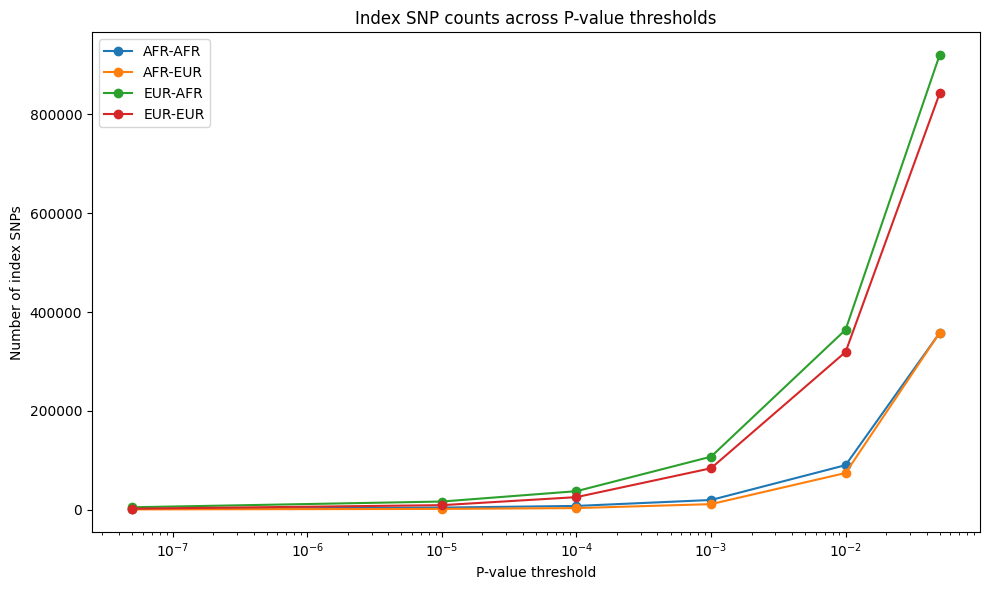

In [ ]:
# Index SNP counts across thresholds
plt.figure(figsize=(10, 6))

for pipeline in ld_summary["Pipeline"].unique():

    subset = ld_summary[
        ld_summary["Pipeline"] == pipeline
    ]

    plt.plot(
        subset["P_threshold"],
        subset["Index_SNPs"],
        marker="o",
        label=pipeline
    )

plt.xscale("log")
plt.xlabel("P-value threshold")
plt.ylabel("Number of index SNPs")
plt.title("Index SNP counts across P-value thresholds")
plt.legend()
plt.tight_layout()
plt.show()

## Plot retention rates

Does one ancestry-matched LD reference consistently retain a different proportion of candidate variants than the ancestry-mismatched reference?

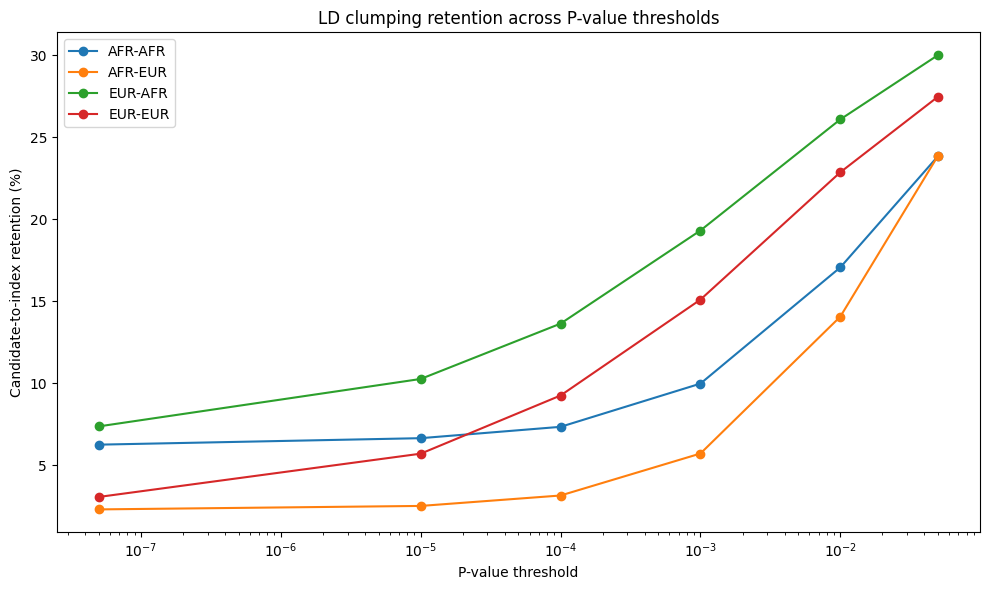

In [ ]:
# Retention rate across thresholds

plt.figure(figsize=(10, 6))

for pipeline in ld_summary["Pipeline"].unique():

    subset = ld_summary[
        ld_summary["Pipeline"] == pipeline
    ]

    plt.plot(
        subset["P_threshold"],
        subset["Retention_Rate_pct"],
        marker="o",
        label=pipeline
    )

plt.xscale("log")
plt.xlabel("P-value threshold")
plt.ylabel("Candidate-to-index retention (%)")
plt.title("LD clumping retention across P-value thresholds")
plt.legend()
plt.tight_layout()
plt.show()

## Plot index-SNP Jaccard similarity

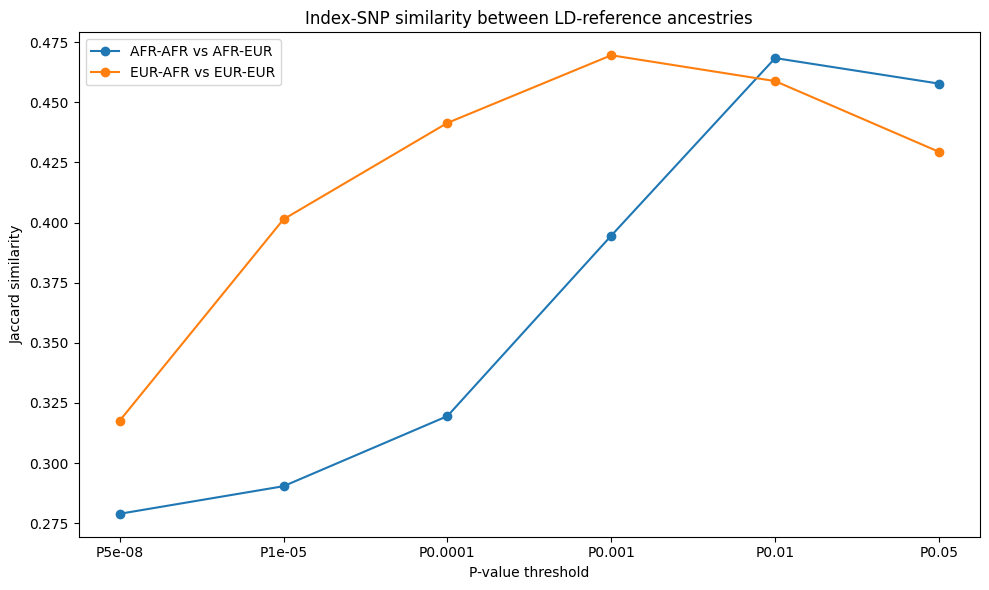

In [ ]:
# Jaccard similarity

plt.figure(figsize=(10, 6))

plt.plot(
    range(len(afr_overlap)),
    afr_overlap["Jaccard"],
    marker="o",
    label="AFR-AFR vs AFR-EUR"
)

plt.plot(
    range(len(eur_overlap)),
    eur_overlap["Jaccard"],
    marker="o",
    label="EUR-AFR vs EUR-EUR"
)

plt.xticks(
    range(len(THRESHOLDS)),
    list(THRESHOLDS.keys())
)

plt.xlabel("P-value threshold")
plt.ylabel("Jaccard similarity")
plt.title("Index-SNP similarity between LD-reference ancestries")
plt.legend()
plt.tight_layout()
plt.show()


## Direct same-GWAS LD comparison table

In [ ]:
# LD-reference comparison summary

ld_comparison_records = []

for threshold in THRESHOLDS:

    afr_row = ld_summary[
        (ld_summary["Threshold"] == threshold) &
        (ld_summary["Pipeline"] == "AFR-AFR")
    ].iloc[0]

    afr_eur_row = ld_summary[
        (ld_summary["Threshold"] == threshold) &
        (ld_summary["Pipeline"] == "AFR-EUR")
    ].iloc[0]

    eur_afr_row = ld_summary[
        (ld_summary["Threshold"] == threshold) &
        (ld_summary["Pipeline"] == "EUR-AFR")
    ].iloc[0]

    eur_eur_row = ld_summary[
        (ld_summary["Threshold"] == threshold) &
        (ld_summary["Pipeline"] == "EUR-EUR")
    ].iloc[0]

    afr_overlap_row = afr_overlap[
        afr_overlap["Threshold"] == threshold
    ].iloc[0]

    eur_overlap_row = eur_overlap[
        eur_overlap["Threshold"] == threshold
    ].iloc[0]

    ld_comparison_records.append({
        "Threshold": threshold,

        "AFR_GWAS_AFR_LD_Index": afr_row["Index_SNPs"],
        "AFR_GWAS_EUR_LD_Index": afr_eur_row["Index_SNPs"],

        "AFR_GWAS_AFR_LD_Retention_pct":
            afr_row["Retention_Rate_pct"],

        "AFR_GWAS_EUR_LD_Retention_pct":
            afr_eur_row["Retention_Rate_pct"],

        "AFR_Index_Shared":
            afr_overlap_row["Shared"],

        "AFR_Index_Jaccard":
            afr_overlap_row["Jaccard"],

        "EUR_GWAS_AFR_LD_Index":
            eur_afr_row["Index_SNPs"],

        "EUR_GWAS_EUR_LD_Index":
            eur_eur_row["Index_SNPs"],

        "EUR_GWAS_AFR_LD_Retention_pct":
            eur_afr_row["Retention_Rate_pct"],

        "EUR_GWAS_EUR_LD_Retention_pct":
            eur_eur_row["Retention_Rate_pct"],

        "EUR_Index_Shared":
            eur_overlap_row["Shared"],

        "EUR_Index_Jaccard":
            eur_overlap_row["Jaccard"]
    })

ld_comparison_summary = pd.DataFrame(
    ld_comparison_records
)

ld_comparison_summary

,Threshold,AFR_GWAS_AFR_LD_Index,AFR_GWAS_EUR_LD_Index,AFR_GWAS_AFR_LD_Retention_pct,AFR_GWAS_EUR_LD_Retention_pct,AFR_Index_Shared,AFR_Index_Jaccard,EUR_GWAS_AFR_LD_Index,EUR_GWAS_EUR_LD_Index,EUR_GWAS_AFR_LD_Retention_pct,EUR_GWAS_EUR_LD_Retention_pct,EUR_Index_Shared,EUR_Index_Jaccard
0,P5e-08,1710,633,6.265572,2.319361,511,0.278930,4944,2063,7.379545,3.079288,1689,0.317601
1,P1e-05,4305,1636,6.660169,2.531019,1337,0.290400,16558,9216,10.269419,5.715845,7382,0.401370
2,P0.0001,7666,3302,7.351785,3.166657,2656,0.319538,37511,25465,13.641604,9.260842,19286,0.441428
3,P0.001,19691,11288,9.985243,5.724109,8765,0.394571,107335,83925,19.316668,15.103661,61112,0.469558
4,P0.01,90187,74325,17.066455,14.064824,52476,0.468385,364262,319256,26.087698,22.864460,214974,0.458813
5,P0.05,357804,358128,23.850627,23.872224,224817,0.457769,920240,842495,30.009682,27.474362,529536,0.429400


## Calculate the magnitude of the LD-reference effect

In [ ]:
# Difference in retention rates

ld_comparison_summary[
    "AFR_Retention_Difference_pct_points"
] = (
    ld_comparison_summary[
        "AFR_GWAS_EUR_LD_Retention_pct"
    ]
    -
    ld_comparison_summary[
        "AFR_GWAS_AFR_LD_Retention_pct"
    ]
)

ld_comparison_summary[
    "EUR_Retention_Difference_pct_points"
] = (
    ld_comparison_summary[
        "EUR_GWAS_EUR_LD_Retention_pct"
    ]
    -
    ld_comparison_summary[
        "EUR_GWAS_AFR_LD_Retention_pct"
    ]
)

ld_comparison_summary

,Threshold,AFR_GWAS_AFR_LD_Index,AFR_GWAS_EUR_LD_Index,AFR_GWAS_AFR_LD_Retention_pct,AFR_GWAS_EUR_LD_Retention_pct,AFR_Index_Shared,AFR_Index_Jaccard,EUR_GWAS_AFR_LD_Index,EUR_GWAS_EUR_LD_Index,EUR_GWAS_AFR_LD_Retention_pct,EUR_GWAS_EUR_LD_Retention_pct,EUR_Index_Shared,EUR_Index_Jaccard,AFR_Retention_Difference_pct_points,EUR_Retention_Difference_pct_points
0,P5e-08,1710,633,6.265572,2.319361,511,0.278930,4944,2063,7.379545,3.079288,1689,0.317601,-3.946211,-4.300257
1,P1e-05,4305,1636,6.660169,2.531019,1337,0.290400,16558,9216,10.269419,5.715845,7382,0.401370,-4.129150,-4.553574
2,P0.0001,7666,3302,7.351785,3.166657,2656,0.319538,37511,25465,13.641604,9.260842,19286,0.441428,-4.185128,-4.380762
3,P0.001,19691,11288,9.985243,5.724109,8765,0.394571,107335,83925,19.316668,15.103661,61112,0.469558,-4.261135,-4.213008
4,P0.01,90187,74325,17.066455,14.064824,52476,0.468385,364262,319256,26.087698,22.864460,214974,0.458813,-3.001631,-3.223237
5,P0.05,357804,358128,23.850627,23.872224,224817,0.457769,920240,842495,30.009682,27.474362,529536,0.429400,0.021597,-2.535320


## Examine threshold nesting

As the P-value threshold becomes more permissive, candidate SNP sets should generally expand.

The index sets, however, do not necessarily have to be perfectly nested in the same way because LD clumping can cause the selected index SNP to change when additional candidates become available.


In [ ]:
#Index count progression
index_progression = (
    index_counts
    .sort_values(
        ["Pipeline", "P_threshold"]
    )
)

display(index_progression)

,Pipeline,Threshold,P_threshold,Index_SNPs
5,AFR-AFR,P5e-08,5.000000e-08,1710
4,AFR-AFR,P1e-05,1.000000e-05,4305
0,AFR-AFR,P0.0001,1.000000e-04,7666
1,AFR-AFR,P0.001,1.000000e-03,19691
2,AFR-AFR,P0.01,1.000000e-02,90187
3,AFR-AFR,P0.05,5.000000e-02,357804
11,AFR-EUR,P5e-08,5.000000e-08,633
10,AFR-EUR,P1e-05,1.000000e-05,1636
6,AFR-EUR,P0.0001,1.000000e-04,3302
7,AFR-EUR,P0.001,1.000000e-03,11288


# Final QC

In [ ]:
print("Final Notebook 06 QC\n")

print("Candidate count records:", len(candidate_counts))
print("Index count records:", len(index_counts))
print("Thresholds:", len(THRESHOLDS))
print("Pipelines:", len(LD_DIRS))

print(
    "\nExpected candidate-count records:",
    len(THRESHOLDS) * len(CANDIDATE_DIRS)
)

print(
    "Expected index-count records:",
    len(THRESHOLDS) * len(LD_DIRS)
)

print(
    "\nMissing clump files:",
    (~clump_inventory["Exists"]).sum()
)

print(
    "Duplicate index records:",
    len(duplicate_index_records)
)

Final Notebook 06 QC

Candidate count records: 24
Index count records: 24
Thresholds: 6
Pipelines: 4

Expected candidate-count records: 24
Expected index-count records: 24

Missing clump files: 2
Duplicate index records: 0


## Explicit same-GWAS candidate consistency check

In [ ]:
# Candidate-set consistency

candidate_consistency = (
    candidate_counts
    .pivot(
        index="Threshold",
        columns="Pipeline",
        values="Candidate_SNPs"
    )
)

candidate_consistency["AFR_same_GWAS_equal"] = (
    candidate_consistency["AFR-AFR"]
    ==
    candidate_consistency["AFR-EUR"]
)

candidate_consistency["EUR_same_GWAS_equal"] = (
    candidate_consistency["EUR-AFR"]
    ==
    candidate_consistency["EUR-EUR"]
)

display(candidate_consistency)

Pipeline,AFR-AFR,AFR-EUR,EUR-AFR,EUR-EUR,AFR_same_GWAS_equal,EUR_same_GWAS_equal
Threshold,,,,,,
P0.0001,104274,104274,274975,274975,True,True
P0.001,197201,197201,555660,555660,True,True
P0.01,528446,528446,1396298,1396298,True,True
P0.05,1500187,1500187,3066477,3066477,True,True
P1e-05,64638,64638,161236,161236,True,True
P5e-08,27292,27292,66996,66996,True,True


# Saving results

In [ ]:
COMPARISON_DIR = Path(
    "/content/drive/MyDrive/PRS_T2D_comparison/PRS_LD_Clumping_Comparison"
)

COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory:")
print(COMPARISON_DIR)

Output directory:
/content/drive/MyDrive/PRS_T2D_comparison/PRS_LD_Clumping_Comparison


In [ ]:
# Saving the main tables

ld_summary.to_csv(
    COMPARISON_DIR / "LD_clumping_summary.tsv",
    sep="\t",
    index=False
)

afr_overlap.to_csv(
    COMPARISON_DIR / "AFR_GWAS_index_overlap.tsv",
    sep="\t",
    index=False
)

eur_overlap.to_csv(
    COMPARISON_DIR / "EUR_GWAS_index_overlap.tsv",
    sep="\t",
    index=False
)

chromosome_summary.to_csv(
    COMPARISON_DIR / "chromosome_index_summary.tsv",
    sep="\t",
    index=False
)

ld_comparison_summary.to_csv(
    COMPARISON_DIR / "LD_reference_comparison_summary.tsv",
    sep="\t",
    index=False
)

print("Main Notebook 06 tables saved.")

Main Notebook 06 tables saved.


In [ ]:
# Save index SNP records

index_snps.to_csv(
    COMPARISON_DIR / "LD_comparison_all_index_SNPs.tsv.gz",
    sep="\t",
    index=False,
    compression="gzip"
)

print(
    "Saved:",
    COMPARISON_DIR / "LD_comparison_all_index_SNPs.tsv.gz"
)

Saved: /content/drive/MyDrive/PRS_T2D_comparison/PRS_LD_Clumping_Comparison/LD_comparison_all_index_SNPs.tsv.gz


##Saving figures

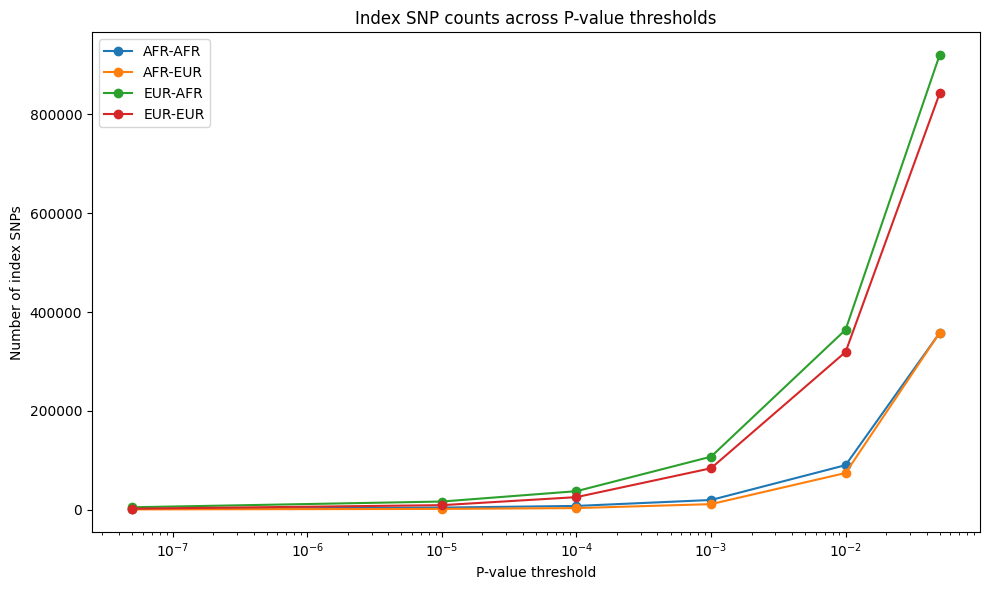

In [ ]:
# Index-count
FIGURE_DIR = COMPARISON_DIR / "figures"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

plt.figure(figsize=(10, 6))

for pipeline in ld_summary["Pipeline"].unique():

    subset = ld_summary[
        ld_summary["Pipeline"] == pipeline
    ]

    plt.plot(
        subset["P_threshold"],
        subset["Index_SNPs"],
        marker="o",
        label=pipeline
    )

plt.xscale("log")
plt.xlabel("P-value threshold")
plt.ylabel("Number of index SNPs")
plt.title("Index SNP counts across P-value thresholds")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "index_SNP_counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

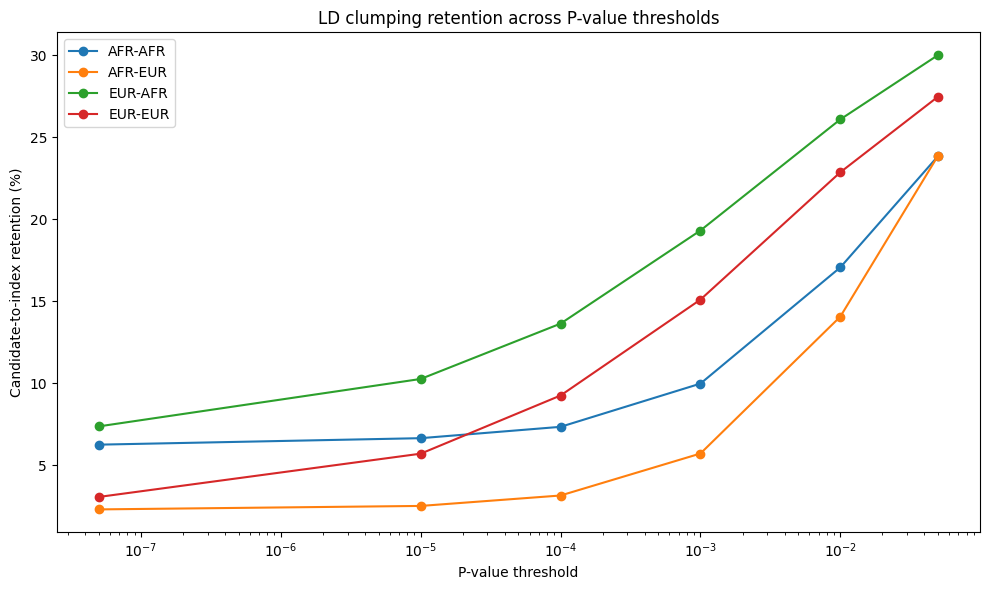

In [ ]:
# retention-rate
plt.figure(figsize=(10, 6))

for pipeline in ld_summary["Pipeline"].unique():

    subset = ld_summary[
        ld_summary["Pipeline"] == pipeline
    ]

    plt.plot(
        subset["P_threshold"],
        subset["Retention_Rate_pct"],
        marker="o",
        label=pipeline
    )

plt.xscale("log")
plt.xlabel("P-value threshold")
plt.ylabel("Candidate-to-index retention (%)")
plt.title("LD clumping retention across P-value thresholds")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "retention_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

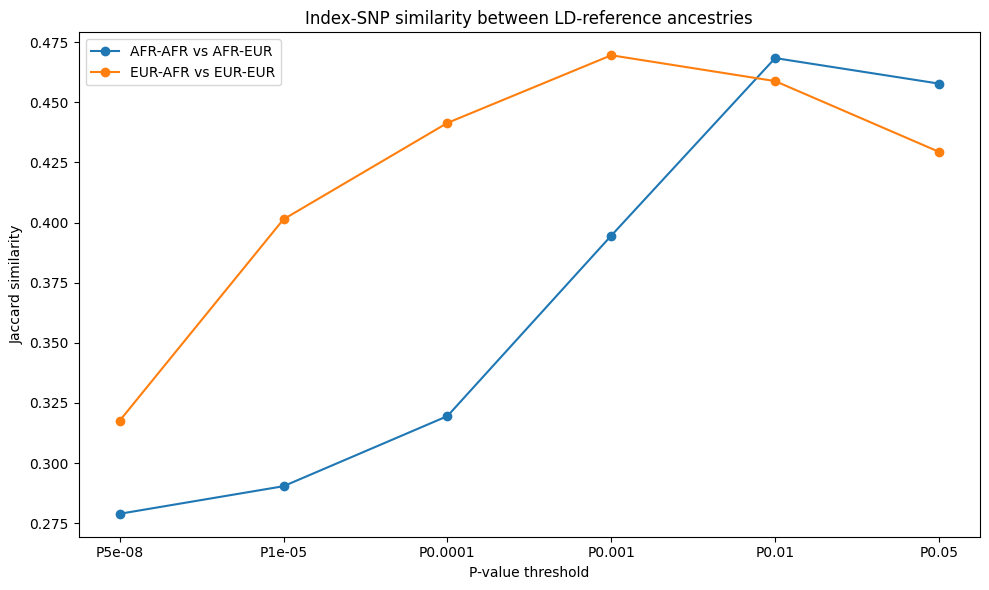

In [ ]:
# Jaccard

plt.figure(figsize=(10, 6))

plt.plot(
    range(len(afr_overlap)),
    afr_overlap["Jaccard"],
    marker="o",
    label="AFR-AFR vs AFR-EUR"
)

plt.plot(
    range(len(eur_overlap)),
    eur_overlap["Jaccard"],
    marker="o",
    label="EUR-AFR vs EUR-EUR"
)

plt.xticks(
    range(len(THRESHOLDS)),
    list(THRESHOLDS.keys())
)

plt.xlabel("P-value threshold")
plt.ylabel("Jaccard similarity")
plt.title("Index-SNP similarity between LD-reference ancestries")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "index_SNP_Jaccard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

When the discovery GWAS is held constant, changing the ancestry of the LD reference substantially alters both the number and identity of approximately independent variants retained during T2D PRS construction, particularly at stringent and intermediate P-value thresholds.

Also because the candidate SNP sets were identical within each GWAS ancestry, these downstream differences cannot be attributed to differences in candidate selection and are instead consistent with ancestry-dependent LD structure influencing the clumping stage.

**Finding 1**: LD-reference ancestry clearly changes the number of retained index SNPs

For the African GWAS:

Threshold	AFR LD	EUR LD
5e-8	1,710	633
1e-5	4,305	1,636
1e-4	7,666	3,302
1e-3	19,691	11,288
0.01	90,187	74,325
0.05	357,804	358,128

For the European GWAS:

Threshold	AFR LD	EUR LD
5e-8	4,944	2,063
1e-5	16,558	9,216
1e-4	37,511	25,465
1e-3	107,335	83,925
0.01	364,262	319,256
0.05	920,240	842,495

These are not small differences at the stringent and intermediate thresholds.

For example, with the African GWAS at P ≤ 5e-8:

1,710 vs 633 index SNPs.

That is a very substantial difference caused by changing the LD reference while keeping the GWAS fixed.

The same pattern occurs with the European GWAS.

This supports:

LD-reference ancestry materially influences the number of variants retained after LD clumping.


**Finding 2**: the retention rates show that this is not simply because the candidate sets differ

This is an especially important result because PRS candidate comparison showed that the candidate sets are identical within each GWAS.

For African GWAS:

Threshold	AFR LD retention	EUR LD retention
5e-8	6.27%	2.32%
1e-5	6.66%	2.53%
1e-4	7.35%	3.17%
1e-3	9.99%	5.72%
0.01	17.07%	14.06%
0.05	23.85%	23.87%

For European GWAS:

Threshold	AFR LD retention	EUR LD retention
5e-8	7.38%	3.08%
1e-5	10.27%	5.72%
1e-4	13.64%	9.26%
1e-3	19.32%	15.10%
0.01	26.09%	22.86%
0.05	30.01%	27.47%

This is important because you are normalizing:

index SNPs / candidate SNPs

Since the candidate pool is the same within each GWAS, the difference in retention is directly informative about the different LD-based reduction of that candidate pool.

The most striking point is that the LD-reference effect is strongest at stringent/intermediate thresholds and becomes smaller at P=0.05.

For example:

AFR GWAS, 5e-8: 6.27% vs 2.32%
AFR GWAS, 0.05: 23.85% vs 23.87%

And:

EUR GWAS, 5e-8: 7.38% vs 3.08%
EUR GWAS, 0.05: 30.01% vs 27.47%

So the impact of LD-reference ancestry is threshold-dependent.

**Finding 3**: the LD references do not simply select different numbers of SNPs — they select different SNPs

This is where Jaccard analysis becomes very important.

For the African GWAS:

Threshold	Shared	Jaccard
5e-8	511	0.279
1e-5	1,337	0.290
1e-4	2,656	0.320
1e-3	8,765	0.395
0.01	52,476	0.468
0.05	224,817	0.458

For the European GWAS:

Threshold	Shared	Jaccard
5e-8	1,689	0.318
1e-5	7,382	0.401
1e-4	19,286	0.441
1e-3	61,112	0.470
0.01	214,974	0.459
0.05	529,536	0.429

This means:

The LD-reference ancestry changes the identity of the approximately independent variants, not merely their total number.

At P ≤ 5e-8, for example:

AFR GWAS: only 511 index SNPs are shared.
AFR-LD produces 1,710 index SNPs.
EUR-LD produces 633.

The Jaccard similarity is only 0.279.

For the European GWAS, the corresponding Jaccard is 0.318.

That's a substantial difference in the selected variant sets.

**Finding 4**: the LD-reference effect is not constant across P-value thresholds

The retention differences quantify this nicely.

For the African GWAS, EUR-LD minus AFR-LD retention is approximately:

5e-8: −3.95 percentage points
1e-5: −4.13
1e-4: −4.19
1e-3: −4.26
0.01: −3.00
0.05: +0.02

For the European GWAS:

5e-8: −4.30
1e-5: −4.55
1e-4: −4.38
1e-3: −4.21
0.01: −3.22
0.05: −2.54

So there is a very clear pattern:

The LD-reference effect is large at stringent thresholds and becomes smaller as the candidate pool becomes very large.

**Finding 5**: the effect occurs in both GWAS ancestry contexts

You don't only see the phenomenon with the African GWAS.

You see it in:

African GWAS
AFR LD ≠ EUR LD

and

European GWAS
AFR LD ≠ EUR LD

Therefore the observation is not restricted to one discovery-GWAS ancestry.

However, the magnitude differs between the two contexts.

**Finding 6**: the effect is genome-wide, not obviously confined to one chromosome

We calculated chromosome-level candidate counts, index counts and retention rates.

That allows us to ask whether the differences are concentrated in one chromosome or distributed across the genome.

Differences in index-SNP retention were observed across the genome, with chromosome-level retention varying between LD-reference configurations.

**Finding 7:** the threshold progression behaves as expected

Index SNP counts increase as the P-value threshold becomes more permissive:

5e-8 → 1e-5 → 1e-4 → 1e-3 → 0.01 → 0.05

For example:

AFR-AFR:

1,710
4,305
7,666
19,691
90,187
357,804

AFR-EUR:

633
1,636
3,302
11,288
74,325
358,128

and similarly for the EUR-GWAS configurations.

So increasing the candidate pool produces increasing numbers of independent variants, as expected.